# EDA on the Pima Indians Diabetes Dataset

**Course:** Introduction to Data Science (Lecture 6 - EDA)

In this notebook I do a full Exploratory Data Analysis on a real medical dataset. I followed the same flow as the lecture: first understand the data and the target, then look at single features, then two features together, then correlations, then many features together, and at the end I write down what I found.

## 1. Dataset Introduction

**Dataset:** Pima Indians Diabetes Database

**Source:** Originally from the National Institute of Diabetes and Digestive and Kidney Diseases (UCI / Kaggle). I am loading the CSV copy from the public plotly datasets repo: https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv

The data has medical measurements of women (at least 21 years old, of Pima Indian heritage). 

**Problem I want to explore:** Which health measurements are linked with a woman having diabetes, and is the data clean enough to be used for a prediction model later?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)

url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
df = pd.read_csv(url)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
print("Rows, Columns:", df.shape)
print()
df.info()

Rows, Columns: (768, 9)

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [3]:
print("Missing values (NaN):", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe().T.round(2)

Missing values (NaN): 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


**Features (8) and target (1):**

| Column | Meaning |
|---|---|
| Pregnancies | Number of times pregnant |
| Glucose | Plasma glucose concentration (2 hr oral glucose tolerance test) |
| BloodPressure | Diastolic blood pressure (mm Hg) |
| SkinThickness | Triceps skin fold thickness (mm) |
| Insulin | 2-hour serum insulin (mu U/ml) |
| BMI | Body mass index |
| DiabetesPedigreeFunction | A score showing family history of diabetes |
| Age | Age in years |
| **Outcome** | **Target:** 1 = diabetic, 0 = not diabetic |

The dataset has **768 rows and 9 columns**. There are no NaN values and no duplicates, but when I look at `describe()` I see that the **minimum of Glucose, BloodPressure, SkinThickness, Insulin and BMI is 0**. A person cannot have 0 blood pressure or 0 BMI, so these zeros are most likely missing values that were filled with 0. I will check this properly below.

In [4]:
cols_with_fake_zeros = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = (df[cols_with_fake_zeros] == 0).sum()
zero_pct = (zero_counts / len(df) * 100).round(1)
pd.DataFrame({"zero_count": zero_counts, "percent": zero_pct})

,zero_count,percent
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


Insulin has 374 zeros (about 49%) and SkinThickness has 227 (about 30%). These are not real zeros, so I replace them with NaN. I keep the original `df` and make a cleaned copy `data` for the analysis. (Pregnancies = 0 is fine because a woman can have 0 pregnancies.)

In [5]:
data = df.copy()
data[cols_with_fake_zeros] = data[cols_with_fake_zeros].replace(0, np.nan)
data.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

## 2. Univariate EDA

### 2.1 Histograms with density curve (numerical features)

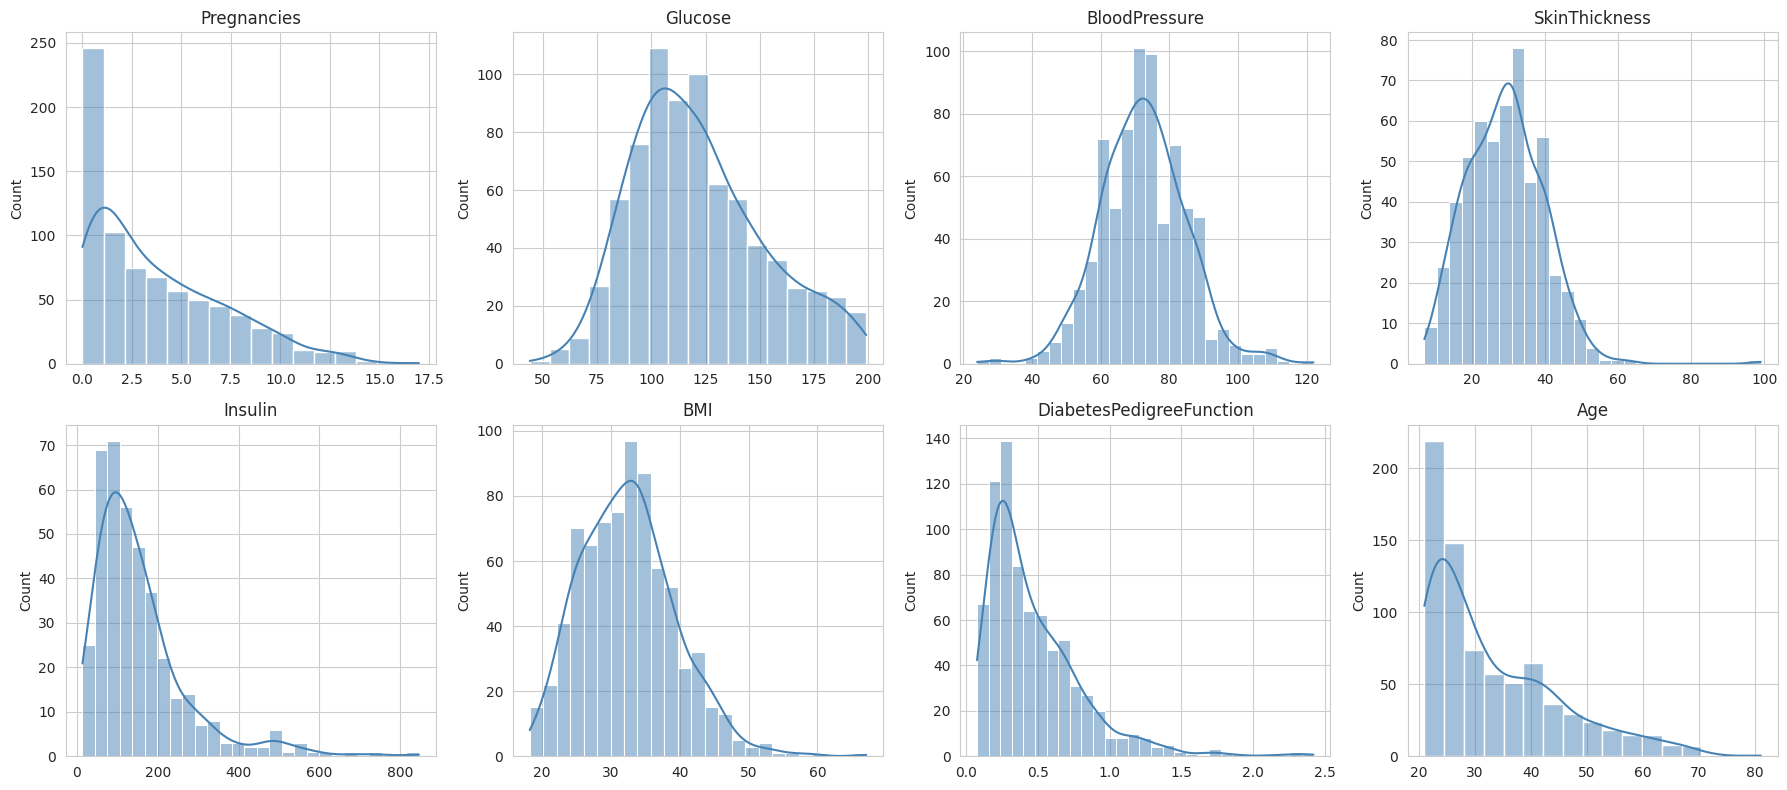

In [6]:
num_cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
            "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data[col].dropna(), kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [7]:
data[num_cols].skew().round(2).sort_values(ascending=False)

Insulin                     2.17
DiabetesPedigreeFunction    1.92
Age                         1.13
Pregnancies                 0.90
SkinThickness               0.69
BMI                         0.59
Glucose                     0.53
BloodPressure               0.13
dtype: float64

**Interpretation:**
- **Glucose, BloodPressure, BMI** look roughly bell shaped (close to normal). Glucose is centered around 115-120.
- **Insulin** (skew about 2.2) and **DiabetesPedigreeFunction** (skew about 1.9) are strongly right skewed. Most people have low values and a few have very high values.
- **Age** (skew about 1.1) and **Pregnancies** (skew about 0.9) are also right skewed. Most women are in their 20s and have 0-3 pregnancies.
- **SkinThickness** (skew about 0.7) and **BMI** (skew about 0.6) are only mildly right skewed after removing the fake zeros.

### 2.2 Boxplots (spread, quartiles, outliers)

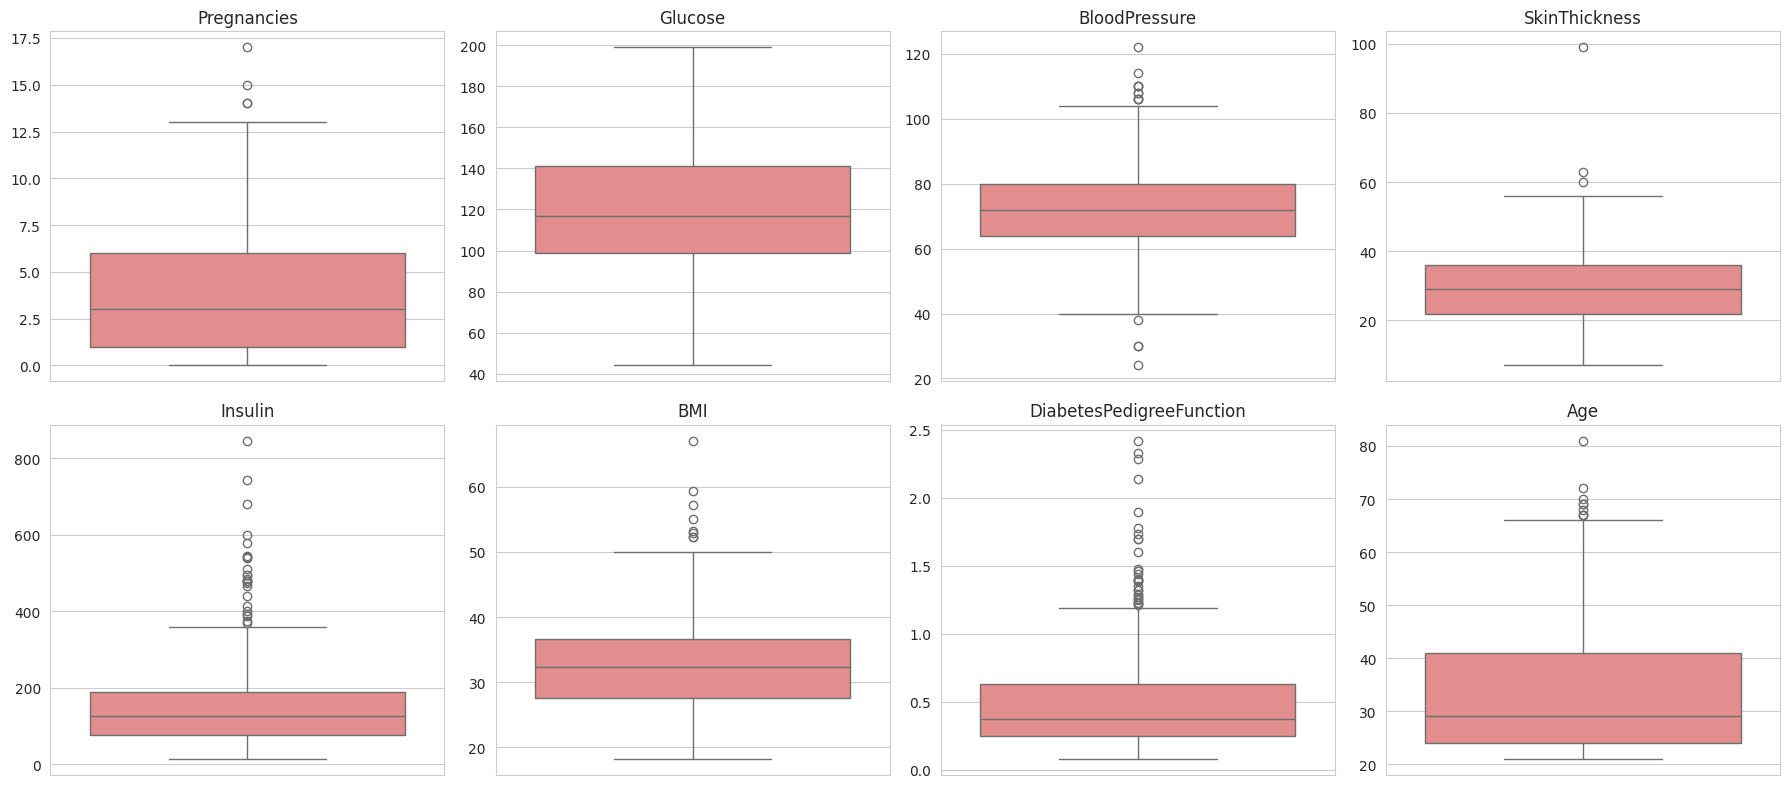

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(y=data[col], ax=ax, color="lightcoral")
    ax.set_title(col)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [9]:
# count outliers with the IQR rule
rows = []
for col in num_cols:
    s = data[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append([col, int(((s < low) | (s > high)).sum()), round(low, 1), round(high, 1)])
pd.DataFrame(rows, columns=["feature", "outliers", "lower_limit", "upper_limit"])

,feature,outliers,lower_limit,upper_limit
0,Pregnancies,4,-6.5,13.5
1,Glucose,0,36.0,204.0
2,BloodPressure,14,40.0,104.0
3,SkinThickness,3,1.0,57.0
4,Insulin,24,-94.4,360.6
5,BMI,8,13.8,50.2
6,DiabetesPedigreeFunction,29,-0.3,1.2
7,Age,9,-1.5,66.5


**Interpretation:**
- **DiabetesPedigreeFunction** (29 outliers) and **Insulin** (24 outliers) have the most outliers, all on the high side. This matches their skewed histograms.
- **BloodPressure** has outliers on both sides (very low values like 24 and a high value of 122).
- **BMI** has a few extreme values, with the maximum at 67.1 which is very high.
- **Glucose** has no outliers by the IQR rule.
- I am not removing these outliers because in medical data extreme values can be real patients and they may actually be important.

### 2.3 Bar chart for a categorical view of the data

The dataset has only numbers, so to make categories I group Age, BMI and Glucose into meaningful bins (standard medical ranges for BMI and glucose).

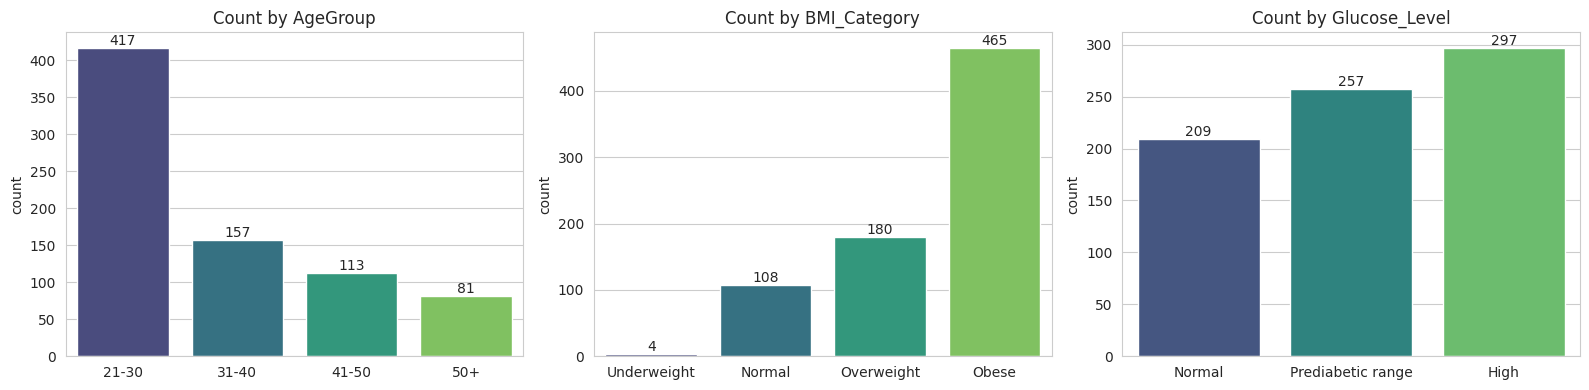

In [10]:
data["AgeGroup"] = pd.cut(data["Age"], bins=[20, 30, 40, 50, 100], labels=["21-30", "31-40", "41-50", "50+"])
data["BMI_Category"] = pd.cut(data["BMI"], bins=[0, 18.5, 25, 30, 100],
                              labels=["Underweight", "Normal", "Overweight", "Obese"])
data["Glucose_Level"] = pd.cut(data["Glucose"], bins=[0, 100, 125, 300],
                               labels=["Normal", "Prediabetic range", "High"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["AgeGroup", "BMI_Category", "Glucose_Level"]):
    sns.countplot(x=data[col], ax=ax, palette="viridis")
    ax.set_title(f"Count by {col}")
    ax.set_xlabel("")
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Interpretation:**
- More than half of the women (417 out of 768) are between 21 and 30 years old, so the data is dominated by young women.
- **465 women (about 61%) are in the Obese BMI category** and only 108 have normal BMI. This sample is not a healthy population in general.
- Only 209 women have normal glucose, the rest are in the prediabetic range or high.

## 3. Target Analysis

         count  percent
Outcome                
0          500     65.1
1          268     34.9


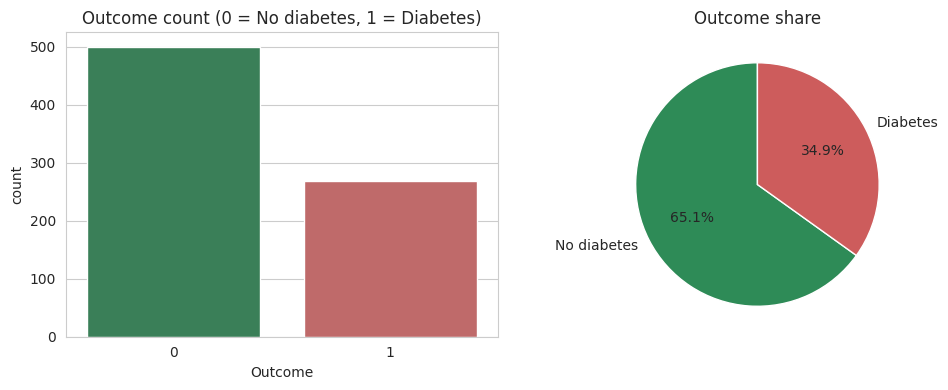

In [11]:
counts = data["Outcome"].value_counts()
percent = data["Outcome"].value_counts(normalize=True).mul(100).round(1)
print(pd.DataFrame({"count": counts, "percent": percent}))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="Outcome", data=data, ax=axes[0], palette=["seagreen", "indianred"])
axes[0].set_title("Outcome count (0 = No diabetes, 1 = Diabetes)")
axes[1].pie(counts, labels=["No diabetes", "Diabetes"], autopct="%1.1f%%",
            colors=["seagreen", "indianred"], startangle=90)
axes[1].set_title("Outcome share")
plt.tight_layout()
plt.show()

**Observation:** 500 women (65.1%) are non-diabetic and 268 (34.9%) are diabetic. The target is **moderately imbalanced** (roughly 2 : 1). It is not extreme like fraud data, but a model that always predicts "No diabetes" would already get about 65% accuracy. So in modeling, accuracy alone is not a good metric and I should also check recall, precision and F1 for the diabetic class.

## 4. Bivariate EDA

### 4.1 Feature vs target (boxplots)

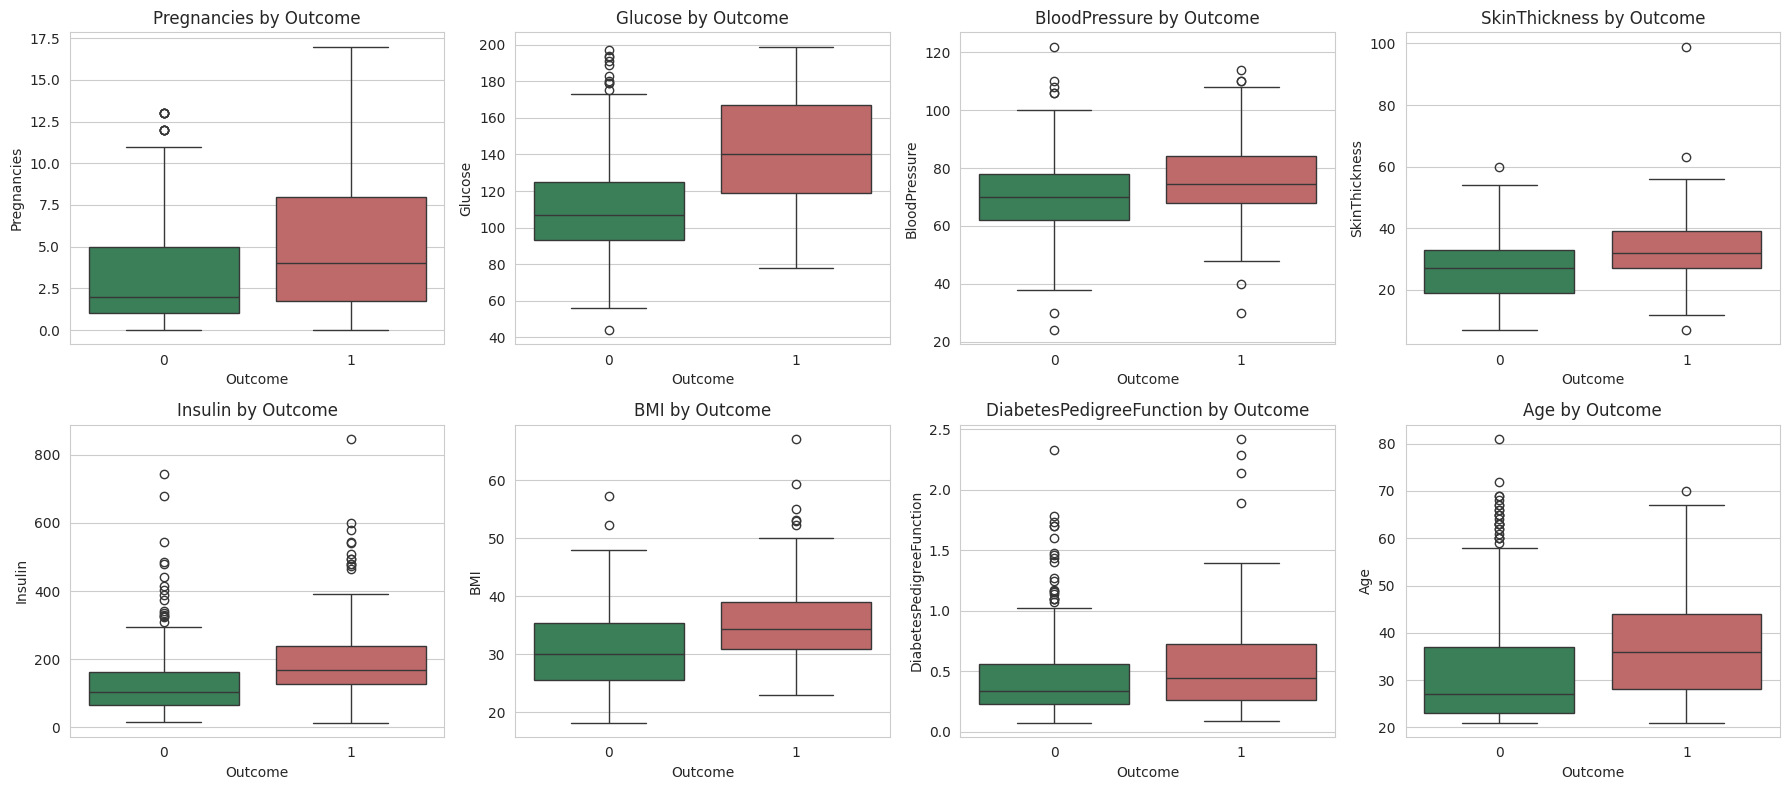

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x="Outcome", y=col, data=data, ax=ax, palette=["seagreen", "indianred"])
    ax.set_title(f"{col} by Outcome")
    ax.set_xlabel("Outcome")
plt.tight_layout()
plt.show()

In [13]:
data.groupby("Outcome")[num_cols].median().round(1).T

Outcome,0,1
Pregnancies,2.0,4.0
Glucose,107.0,140.0
BloodPressure,70.0,74.5
SkinThickness,27.0,32.0
Insulin,102.5,169.5
BMI,30.1,34.3
DiabetesPedigreeFunction,0.3,0.4
Age,27.0,36.0


**Interpretation:**
- **Glucose** shows the biggest difference: the median is 107 for non-diabetic and 140 for diabetic women. The two boxes hardly overlap.
- **Insulin** median is also much higher for diabetic women (about 170 vs 102).
- **BMI, Age and Pregnancies** are also higher for the diabetic group.
- **BloodPressure** and **SkinThickness** show only a small difference, so they will probably be weaker predictors.

### 4.2 Diabetes rate by category (grouped bar chart)

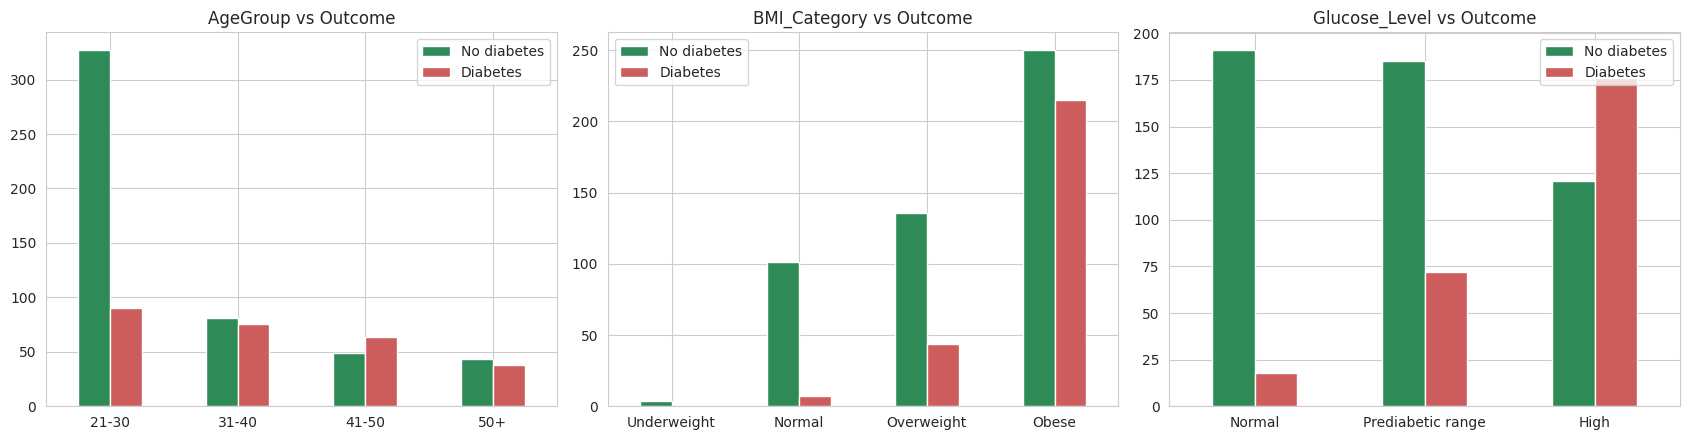

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["AgeGroup", "BMI_Category", "Glucose_Level"]):
    ct = pd.crosstab(data[col], data["Outcome"])
    ct.plot(kind="bar", ax=ax, color=["seagreen", "indianred"], rot=0)
    ax.set_title(f"{col} vs Outcome")
    ax.set_xlabel("")
    ax.legend(["No diabetes", "Diabetes"])
plt.tight_layout()
plt.show()

In [15]:
# diabetes percentage inside each group
for col in ["AgeGroup", "BMI_Category", "Glucose_Level"]:
    print((data.groupby(col)["Outcome"].mean() * 100).round(1).to_string())
    print()

AgeGroup
21-30    21.6
31-40    48.4
41-50    56.6
50+      46.9

BMI_Category
Underweight     0.0
Normal          6.5
Overweight     24.4
Obese          46.2

Glucose_Level
Normal                8.6
Prediabetic range    28.0
High                 59.3



**Interpretation:**
- **Age:** diabetes rate is only about 22% in the 21-30 group but jumps to about 48% for 31-40 and about 57% for 41-50. It does not keep increasing after that (about 47% for 50+, but the group is small with only 81 women).
- **BMI:** the rate goes up very clearly: about 6% for normal BMI, 24% for overweight and 46% for obese.
- **Glucose:** about 9% for normal glucose, 28% for the prediabetic range and 59% for high glucose. This is the strongest pattern so far.

### 4.3 Scatter plots

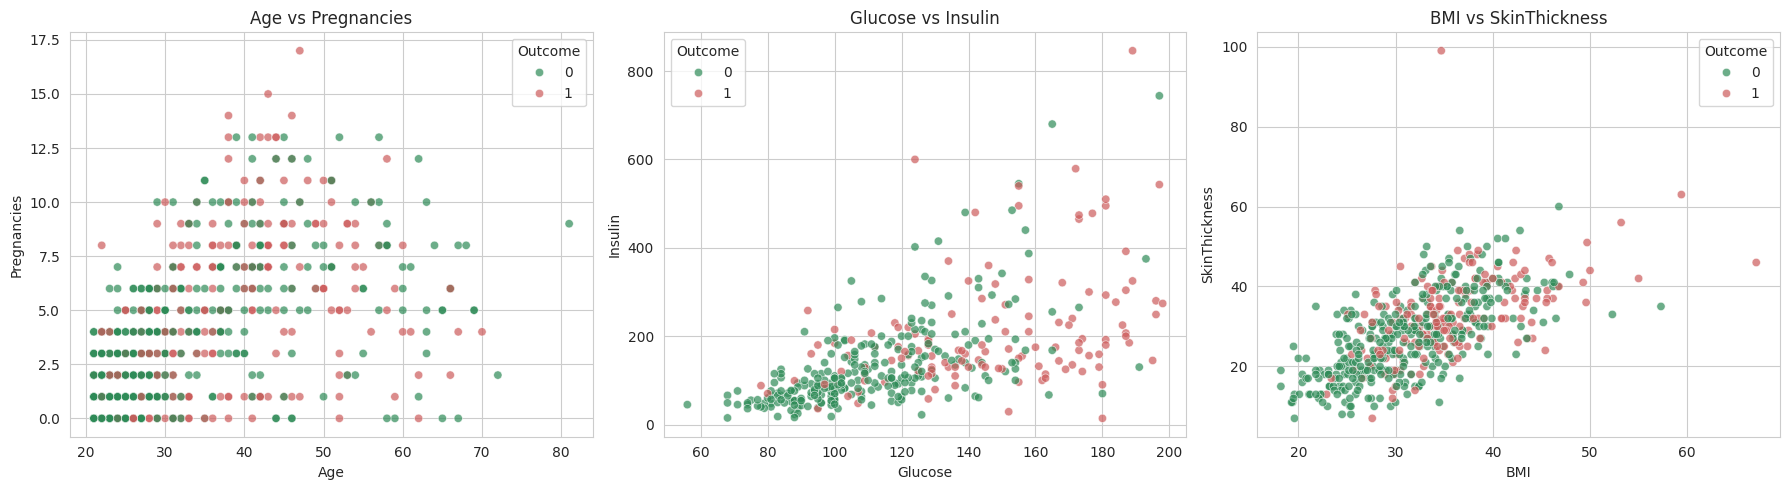

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pairs = [("Age", "Pregnancies"), ("Glucose", "Insulin"), ("BMI", "SkinThickness")]
for ax, (x, y) in zip(axes, pairs):
    sns.scatterplot(data=data, x=x, y=y, hue="Outcome", palette=["seagreen", "indianred"],
                    alpha=0.7, ax=ax)
    ax.set_title(f"{x} vs {y}")
plt.tight_layout()
plt.show()

**Interpretation:**
- **Age vs Pregnancies:** clear upward trend, which is logical because older women have had more time to have children.
- **Glucose vs Insulin:** there is a positive relationship and the red (diabetic) points are mostly in the top right.
- **BMI vs SkinThickness:** positive relationship, as higher body fat gives thicker skin folds. Red points are again more on the higher side.

## 5. Correlation Analysis

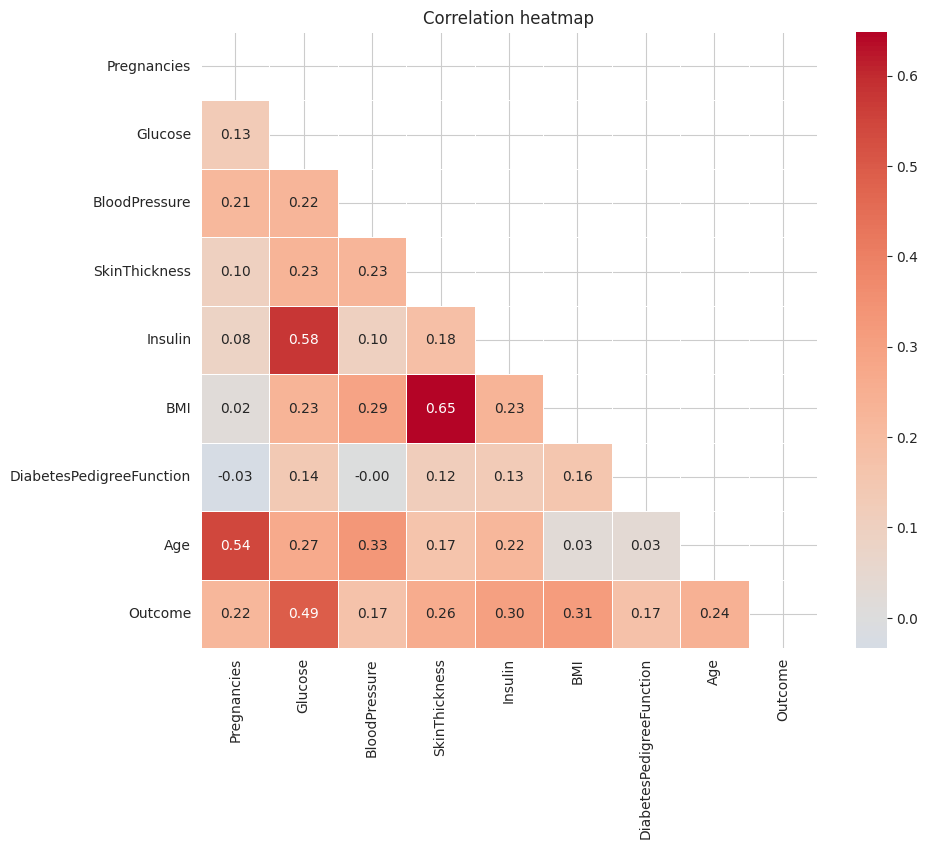

In [17]:
corr = data[num_cols + ["Outcome"]].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, mask=mask,
            linewidths=0.5, square=True)
plt.title("Correlation heatmap")
plt.show()

In [18]:
print("Correlation with Outcome:")
corr["Outcome"].drop("Outcome").sort_values(ascending=False).round(2)

Correlation with Outcome:


Glucose                     0.49
BMI                         0.31
Insulin                     0.30
SkinThickness               0.26
Age                         0.24
Pregnancies                 0.22
DiabetesPedigreeFunction    0.17
BloodPressure               0.17
Name: Outcome, dtype: float64

In [19]:
# strongest pairs between features
pairs = corr.where(np.tril(np.ones(corr.shape), k=-1).astype(bool)).stack()
pairs = pairs.drop(labels=[i for i in pairs.index if "Outcome" in i])
pairs.sort_values(ascending=False).head(5).round(2)

BMI      SkinThickness    0.65
Insulin  Glucose          0.58
Age      Pregnancies      0.54
         BloodPressure    0.33
BMI      BloodPressure    0.29
dtype: float64

**Interpretation:**
- **Strongest with the target:** Glucose (about 0.49) is the clearest one. Then BMI (0.31), Insulin (0.30), SkinThickness (0.26), Age (0.24) and Pregnancies (0.22). These are all positive but moderate.
- **Weak with the target:** DiabetesPedigreeFunction (0.17) and BloodPressure (0.17).
- **Strong positive between features:** BMI and SkinThickness (about 0.65), Glucose and Insulin (about 0.58), Age and Pregnancies (about 0.54).
- **No strong negative correlation** is present in this dataset.
- Since no pair of features is above 0.7, multicollinearity is not a big problem here.
- Note: these correlations are higher than what we get if we keep the fake zeros in the data (for example Insulin-Glucose is only 0.33 with zeros), which shows why cleaning mattered.

## 6. Multivariate EDA

### 6.1 Pairplot of the main features

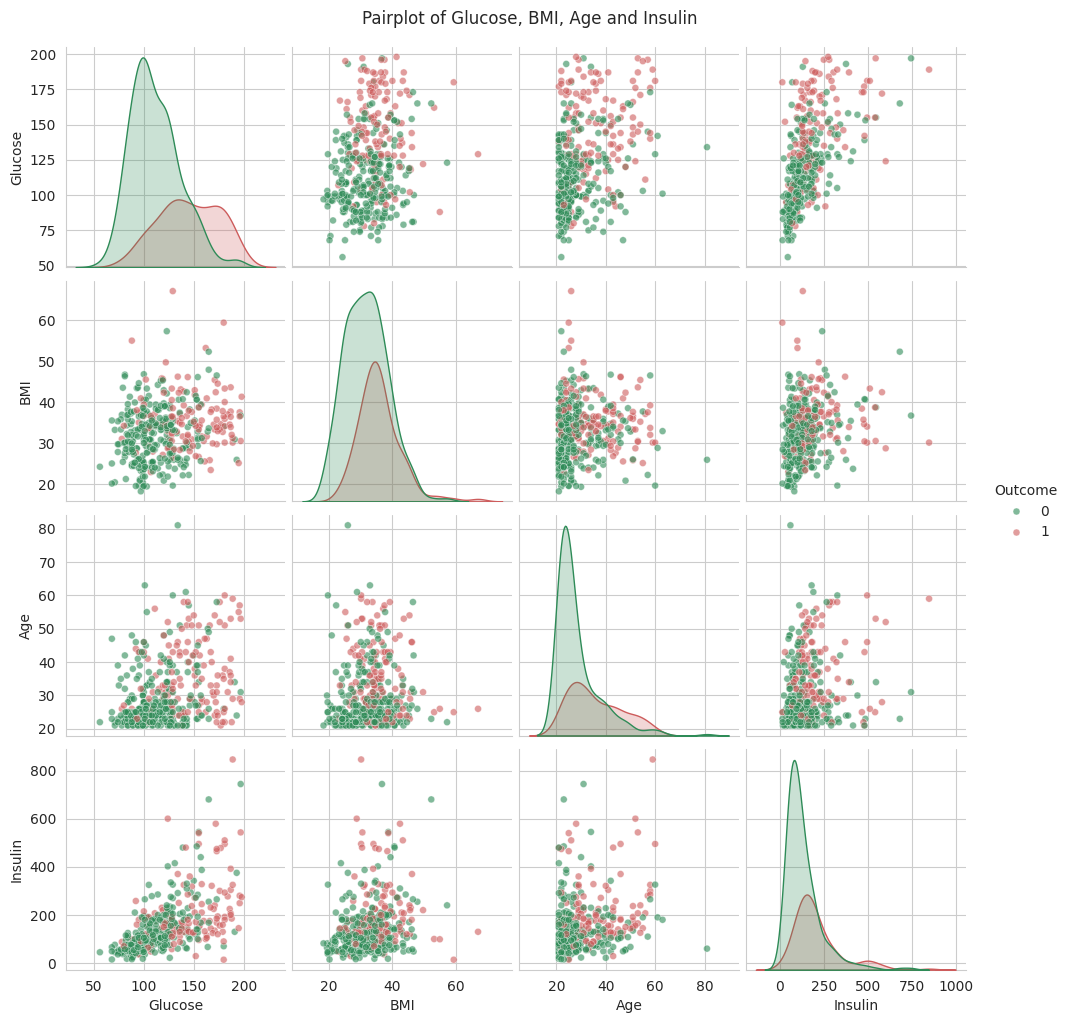

In [20]:
main = ["Glucose", "BMI", "Age", "Insulin"]
g = sns.pairplot(data[main + ["Outcome"]].dropna(), hue="Outcome",
                 palette=["seagreen", "indianred"], diag_kind="kde",
                 plot_kws={"alpha": 0.6, "s": 25})
g.fig.suptitle("Pairplot of Glucose, BMI, Age and Insulin", y=1.02)
plt.show()

**Interpretation:** In every plot that has Glucose, the red and green points separate better than for the other features. Diabetic women are concentrated in the high glucose region. For BMI and Age alone there is a lot of overlap, so one feature is not enough, but combined with glucose they help.

### 6.2 Glucose vs BMI vs Age together

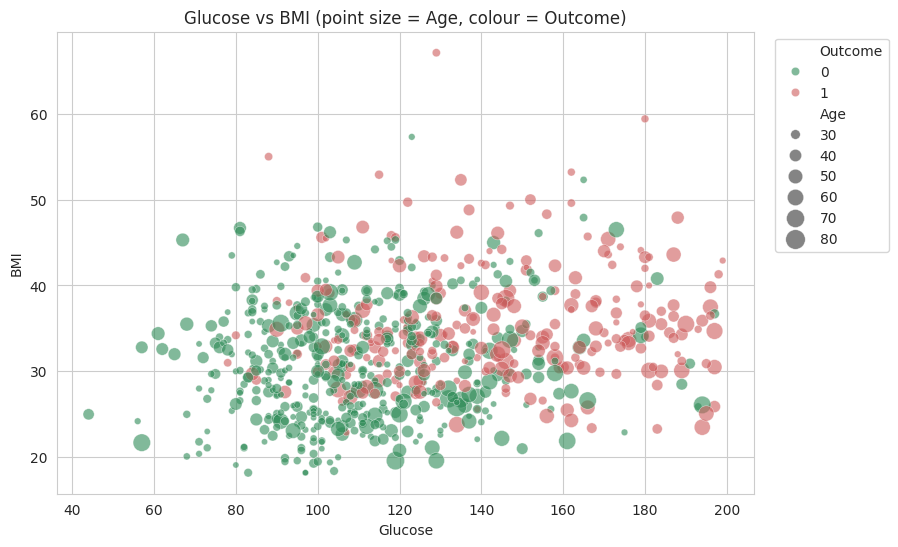

In [21]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=data, x="Glucose", y="BMI", hue="Outcome", size="Age",
                sizes=(20, 200), palette=["seagreen", "indianred"], alpha=0.6)
plt.title("Glucose vs BMI (point size = Age, colour = Outcome)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Interpretation:** The top right corner (high glucose and high BMI) is mostly red, and the bottom left (low glucose and normal BMI) is mostly green. The bigger circles (older women) are more common among the red points too. So the risk grows when high glucose, high BMI and higher age come together.

### 6.3 Diabetes rate by Age Group and BMI Category

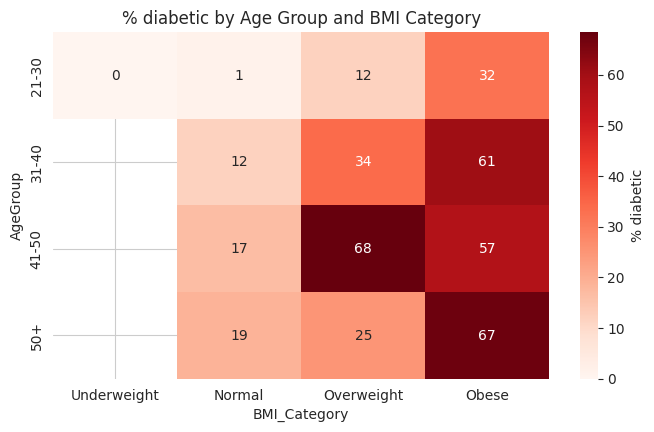

Group sizes:


BMI_Category,Underweight,Normal,Overweight,Obese
AgeGroup,,,,
21-30,4,69,100,235
31-40,0,17,41,99
41-50,0,6,19,88
50+,0,16,20,43


In [22]:
pivot = data.pivot_table(values="Outcome", index="AgeGroup", columns="BMI_Category", aggfunc="mean") * 100
plt.figure(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% diabetic"})
plt.title("% diabetic by Age Group and BMI Category")
plt.show()

print("Group sizes:")
pd.crosstab(data["AgeGroup"], data["BMI_Category"])

**Interpretation:** Young women (21-30) with normal BMI almost never have diabetes (about 1%), while obese women aged 31 and above have 57-67% diabetes rate. Both age and BMI matter, and the effect is combined. Some cells are based on very few women (for example underweight), so those should not be trusted much.

### 6.4 Median profile of both groups

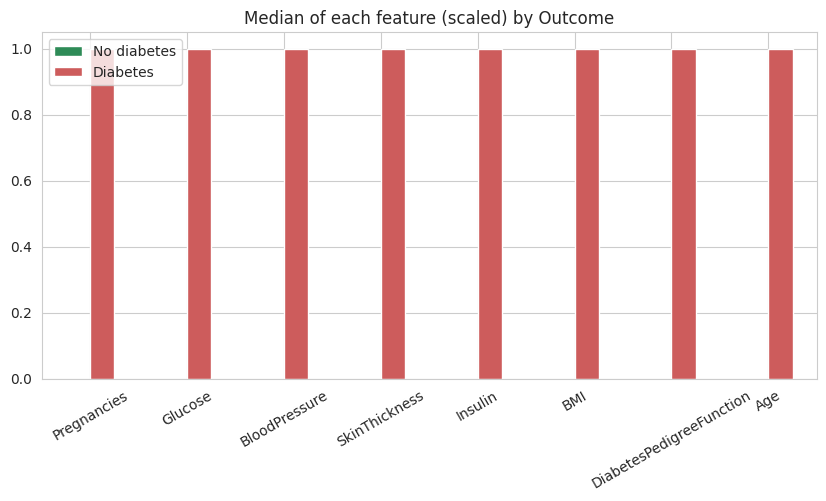

In [23]:
profile = data.groupby("Outcome")[num_cols].median()
# scale to 0-1 so that all features can be seen on one plot
scaled = (profile - profile.min()) / (profile.max() - profile.min())
scaled.T.plot(kind="bar", figsize=(10, 4.5), color=["seagreen", "indianred"], rot=30)
plt.title("Median of each feature (scaled) by Outcome")
plt.legend(["No diabetes", "Diabetes"])
plt.show()

**Interpretation:** The diabetic group is higher on every feature, and the gap is largest for Insulin, Glucose, Pregnancies and Age.

## 7. Patterns, Trends and Anomalies

In [24]:
# 1. Fake zeros
print("Fake zeros in original data:")
print((df[cols_with_fake_zeros] == 0).sum().to_string())
print()

# 2. Extreme values
print("Highest Insulin values:")
print(data.nlargest(3, "Insulin")[["Insulin", "Glucose", "BMI", "Age", "Outcome"]].to_string())
print()
print("Highest Pregnancies values:")
print(data["Pregnancies"].value_counts().sort_index().tail(5).to_string())
print()
print("Highest BMI values:")
print(data.nlargest(3, "BMI")[["BMI", "Glucose", "Age", "Outcome"]].to_string())

Fake zeros in original data:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11

Highest Insulin values:
     Insulin  Glucose   BMI  Age  Outcome
13     846.0    189.0  30.1   59        1
228    744.0    197.0  36.7   31        0
247    680.0    165.0  52.3   23        0

Highest Pregnancies values:
Pregnancies
12     9
13    10
14     2
15     1
17     1

Highest BMI values:
      BMI  Glucose  Age  Outcome
177  67.1    129.0   26        1
445  59.4    180.0   25        1
673  57.3    123.0   22        0


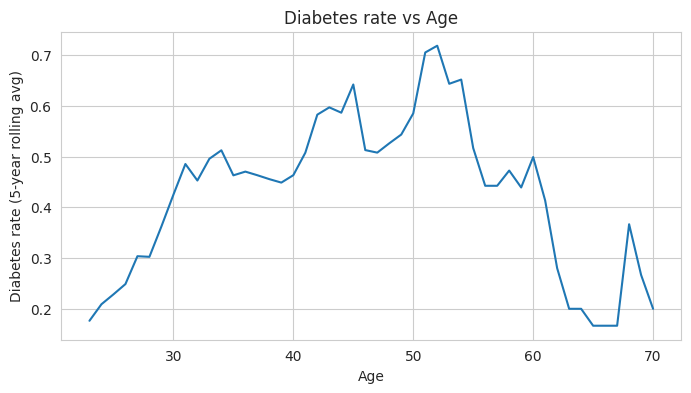

In [25]:
# 3. Diabetes rate across Age (trend)
age_trend = data.groupby("Age")["Outcome"].mean().rolling(5, center=True).mean()
plt.figure(figsize=(8, 4))
age_trend.plot()
plt.ylabel("Diabetes rate (5-year rolling avg)")
plt.title("Diabetes rate vs Age")
plt.show()

**What I noticed:**
- **Anomaly 1 - hidden missing values:** zeros in Glucose (5), BloodPressure (35), SkinThickness (227), Insulin (374) and BMI (11) are impossible values and are really missing data.
- **Anomaly 2 - extreme Insulin:** the maximum is 846, far above the typical range (median about 125 after cleaning). It is a valid but rare case.
- **Anomaly 3 - Pregnancies:** a few women have 14, 15 and 17 pregnancies, which is unusual but possible.
- **Anomaly 4 - BMI of 67.1** is extremely high (very severe obesity) and should be checked.
- **Trend:** diabetes rate rises quickly from the early 20s to about the mid 30s-40s, then becomes unstable because there are very few older women (so the line is noisy after 50).
- **Pattern:** the data is skewed towards young and obese women, so results may not apply to the general population.

## 8. Final Findings

1. **Data quality is the first problem.** There are no NaN values but 5 columns contain impossible zeros. Insulin (about 49%) and SkinThickness (about 30%) have the most. These must be treated as missing and imputed (median is better than mean because of skewness) before modeling.

2. **The target is moderately imbalanced** (65% non-diabetic, 35% diabetic). For modeling I should use stratified train/test split, and judge the model with recall, precision, F1 and ROC-AUC, not only accuracy. Class weights or SMOTE can be tried.

3. **Glucose is the strongest predictor.** It has the highest correlation with Outcome (about 0.49) and the clearest separation in the boxplots. Diabetes rate goes from 9% (normal glucose) to 59% (high glucose).

4. **BMI and Age are the next important factors.** Rate rises from 6% (normal BMI) to 46% (obese), and from 22% (age 21-30) to 57% (age 41-50). Combined, obese women above 30 have 57-67% diabetes rate.

5. **Several features are skewed with outliers** (Insulin, DiabetesPedigreeFunction, Age, Pregnancies). A log or power transform may help linear models and distance based models (like KNN). Tree based models should not need it.

6. **Correlation among features is moderate** (max about 0.65 for BMI-SkinThickness). Multicollinearity is not serious, but Insulin and Glucose carry some shared information.

7. **Weak features:** BloodPressure and DiabetesPedigreeFunction have low correlation with the target alone. They may still help in combination with others, so I would not drop them without testing.

8. **The sample is biased** (mostly young, mostly obese, only one population group), so any model trained on it may not generalize well to other populations.